[*********************100%***********************]  1 of 1 completed


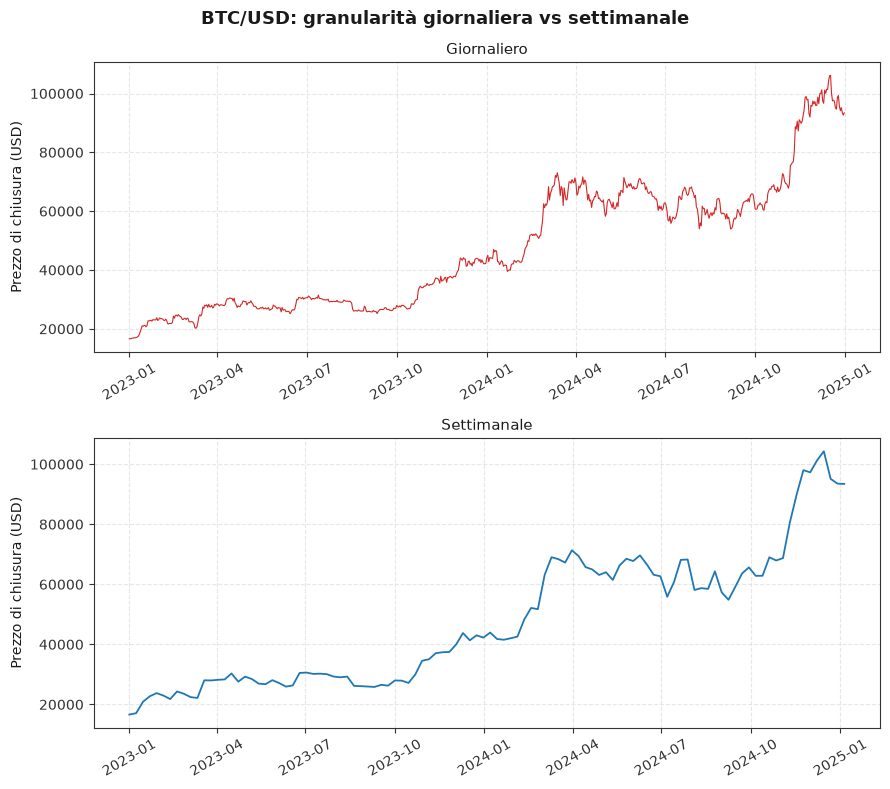

Grafico salvato in docs/assets/daily_weekly.png


In [12]:
"""
Genera un confronto visivo tra la serie di prezzo di BTC/USD a cadenza
giornaliera e la stessa serie ricampionata a cadenza settimanale, per
mostrare empiricamente la differenza di rumore tra le due granularità
(sezione "Formulazione del problema" della Metodologia).

Usa la stessa fonte (yfinance) e la stessa logica di ricampionamento
settimanale (Close: 'last') già impiegate nella pipeline principale
(src/ingestion.py, fetch_market_data), per coerenza metodologica.
"""

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

TICKER = "BTC-USD"
START = "2023-01-01"
END   = "2025-01-01"   # periodo scelto solo a scopo illustrativo: abbastanza
                       # lungo da mostrare la differenza di rumore, non
                       # necessariamente lo stesso periodo usato per il training

OUTPUT_PATH = "docs/assets/daily_weekly.png"


def main():
    daily = yf.download(TICKER, start=START, end=END)
    if isinstance(daily.columns, pd.MultiIndex):
        daily.columns = daily.columns.get_level_values(0)
    daily_close = daily["Close"]

    # Stessa logica di aggregazione della pipeline principale: Close = 'last'
    weekly_close = daily_close.resample("W").last()

    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.edgecolor": "#333333", "axes.labelcolor": "#1a1a1a",
        "xtick.color": "#333333", "ytick.color": "#333333",
        "text.color": "#1a1a1a", "grid.color": "#dddddd",
        "grid.linestyle": "--", "grid.alpha": 0.7,
    })

    fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=False)
    fig.suptitle(
        "BTC/USD: granularità giornaliera vs settimanale",
        fontsize=13, fontweight="bold", color="#1a1a1a"
    )

    axes[0].plot(daily_close.index, daily_close.values, color="#d62728", linewidth=0.8)
    axes[0].set_title(f"Giornaliero", fontsize=11)
    axes[0].set_ylabel("Prezzo di chiusura (USD)")
    axes[0].grid(True)

    axes[1].plot(weekly_close.index, weekly_close.values, color="#1f77b4", linewidth=1.3)
    axes[1].set_title(f"Settimanale", fontsize=11)
    axes[1].set_ylabel("Prezzo di chiusura (USD)")
    axes[1].grid(True)

    for ax in axes:
        ax.tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.savefig(OUTPUT_PATH, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Grafico salvato in {OUTPUT_PATH}")


if __name__ == "__main__":
    main()